# SDXL pipeline: smoke test, pilot (160 images), main generation (2,304 images) & runtime comparison

This notebook runs the SDXL stages of project P40 (`stabilityai/stable-diffusion-xl-base-1.0`, 1024×1024, FP16):
1. **Smoke test (`smoke_sdxl`):** 8 images (`teapot`, seed 0) — technical integration check.
2. **Development pilot (`pilot_sdxl`):** 80 prompts × 2 seeds = 160 images (`mug`, `basket`, `rabbit`), preliminary evaluation (OWLv2 + 8-bit Qwen), 60% singleton quality criterion check, and 24-image human review export (`export-annotations`).
3. **Main SDXL generation (`main_sdxl`):** 576 prompts × 4 seeds = 2,304 images with multi-session coordination and ETA tracking.
4. **Runtime comparison (`SDXL vs SD 1.5`):** per-image generation timing statistics across `main_sd15`, `pilot_sdxl`, and `main_sdxl`.

**Single-writer rule:** Only ONE Colab session may write to a given output directory (`pilot_sdxl` or `main_sdxl`) at a time. Always post in the team chat before starting and after finishing/stopping a session.

**Run order:** Runtime → T4 GPU → cells 1–2 → restart session → cells 1, 3, 4 → desired stage cells. All stages are resumable.

## Repository
Clone the project repository and verify the commit hash.

In [ ]:
import os, sys, subprocess
from pathlib import Path

REPO = Path("/content/cv_project")
if not (REPO / "pyproject.toml").exists():
    subprocess.run(["git", "clone", "https://github.com/IzyumovMaxim/cv_project", str(REPO)], check=True)
os.chdir(REPO)

subprocess.run(["git", "fetch", "-q", "origin"], check=True)
subprocess.run(["git", "checkout", "-q", "363a21c"], check=True)

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "."], check=True)
os.environ["PYTHONPATH"] = str(REPO / "src")
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))
import attribute_interference

## Dependencies
Install the pinned CUDA stack, the project package, and `bitsandbytes==0.47.0` for 8-bit Qwen. **Restart the session afterwards**, then run cells 1, 3, 4.

In [ ]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "-e", "."], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "bitsandbytes==0.47.0"], check=True)
subprocess.run([sys.executable, "-m", "pip", "check"], check=False)
print("Installed. Restart the session, then run cells 1, 3, 4.")

Installed. Restart the session, then run cells 1, 3, 4.


## GPU check

In [ ]:
import torch
assert torch.cuda.is_available(), "Select a GPU runtime"
print(torch.cuda.get_device_name(0), round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1), "GiB")

Tesla T4 14.6 GiB


## Google Drive and helpers
Mount Google Drive (`attribute_interference/v1`) and define helpers for `smoke_sdxl`, `pilot_sdxl`, and `main_sdxl`.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import json, re, statistics
from collections import Counter

OUTPUTS = Path("/content/drive/MyDrive/attribute_interference/v1")
OUTPUTS.mkdir(parents=True, exist_ok=True)
QUANT = "int8"

RUNNER = Path("/content/eval_quant.py")
RUNNER.write_text('''import sys, json, shutil, datetime
from pathlib import Path
import attribute_interference.storage as st
import attribute_interference.evaluation as ev
import attribute_interference.analysis as an

config, root, mode, quant = sys.argv[1], Path(sys.argv[2]), sys.argv[3], sys.argv[4]
assert mode in {'evaluate', 'analyze'} and quant in {'int8', 'nf4'}
cfg = st.load_config(config)
QDIR = f'qwen_{quant}_records'

_records, _put = st.records, st.put_record
def records(r, kind):
    return _records(r, QDIR if kind == 'qwen_records' else kind)
def put_record(r, kind, key, value):
    return _put(r, QDIR if kind == 'qwen_records' else kind, key, value)
ev.records = an.records = records
ev.put_record = put_record

def skip_freeze(cfg, root, frozen):
    marker = Path(root) / 'PRELIMINARY_UNFROZEN.json'
    if not marker.exists():
        st.atomic_json(marker, {
            'note': 'Evaluated WITHOUT a reviewed pilot evaluator freeze. Preliminary results only; '
                    'evaluator accuracy not validated against human labels.',
            'started_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')})
ev.ensure_freeze = skip_freeze

def quantized_init(self, cfg, root, torch):
    from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
    self.torch = torch
    e = cfg['evaluation']
    revision = ev.model_revision(root, 'qwen', e['qwen_checkpoint'], e['qwen_revision'])
    skip = ['visual', 'lm_head']
    if quant == 'int8':
        q = BitsAndBytesConfig(load_in_8bit=True, llm_int8_skip_modules=skip)
    else:
        q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                               bnb_4bit_compute_dtype=torch.float16, llm_int8_skip_modules=skip)
    self.model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        e['qwen_checkpoint'], revision=revision, torch_dtype=torch.float16, attn_implementation='sdpa',
        device_map={'': 0}, quantization_config=q).eval()
    self.processor = AutoProcessor.from_pretrained(e['qwen_checkpoint'], revision=revision,
                                                   min_pixels=256*28*28, max_pixels=e['max_pixels'])
    self.max_tokens = e['max_new_tokens']
ev.QwenEvaluator.__init__ = quantized_init

try:
    if mode == 'evaluate':
        st.atomic_json(root / f'QWEN_{quant.upper()}_NOTE.json', {
            'note': f'Qwen2.5-VL-7B evaluated with bitsandbytes {quant} quantization (deviation from the '
                    'proposal, which specifies FP16 without quantization). Answers in ' + QDIR + '/.'})
        ev.evaluate(cfg, root, 'qwen')
    else:
        an.analyze(cfg, root)
        dest = root / f'analysis_qwen_{quant}'
        if dest.exists():
            shutil.rmtree(dest)
        shutil.copytree(root / 'analysis', dest)
        shutil.copy(root / 'labels.csv', dest / 'labels.csv')
        (dest / 'NOTE.txt').write_text(
            f'Preliminary results: Qwen quantized ({quant}), no reviewed evaluator freeze.\\n'
            'OWLv2 unchanged (FP32). Do not present as the final frozen evaluation.\\n')
        print('Results copied to', dest)
except (ValueError, RuntimeError, FileNotFoundError, ImportError) as exc:
    print(f'ERROR: {exc}', file=sys.stderr)
    sys.exit(1)
''')

OWL_CMD = """
import sys, attribute_interference.evaluation as ev
from attribute_interference.storage import load_config
ev.ensure_freeze = lambda *a: None
try:
    ev.evaluate(load_config(sys.argv[1]), sys.argv[2], "owl")
except (ValueError, RuntimeError, FileNotFoundError, ImportError) as exc:
    print("ERROR:", exc, file=sys.stderr); sys.exit(1)
"""

def stream(cmd, every=10):
    p = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        m = re.search(r"\[(\d+)/(\d+)\].*: (\w+)$", line.strip())
        if m is None or m.group(3) != "ok" or int(m.group(1)) == 1 or int(m.group(1)) % every == 0 or m.group(1) == m.group(2):
            print(line, end="", flush=True)
    if p.wait():
        raise RuntimeError(f"Command failed with exit code {p.returncode}; see the output above")

def run(command, config, name, *extra, every=10):
    cmd = [sys.executable, "-m", "attribute_interference.cli", command,
           "--config", str(REPO / "configs" / (config + ".yaml")),
           "--output", str(OUTPUTS / name), *map(str, extra)]
    stream(cmd, every=every)

def evaluate_run(config, name, backend, every=25):
    cfg_path = str(REPO / "configs" / (config + ".yaml"))
    root_path = str(OUTPUTS / name)
    if backend == "owl":
        stream([sys.executable, "-c", OWL_CMD, cfg_path, root_path], every=every)
    else:
        stream([sys.executable, str(RUNNER), cfg_path, root_path, "evaluate", QUANT], every=every)

def analyze_run(config, name):
    cfg_path = str(REPO / "configs" / (config + ".yaml"))
    root_path = str(OUTPUTS / name)
    stream([sys.executable, str(RUNNER), cfg_path, root_path, "analyze", QUANT])

def summary_and_eta(name, expected_total):
    root = OUTPUTS / name
    rec_dir = root / "generation_records"
    if not rec_dir.exists():
        print(f"[{name}] Directory not initialized yet.")
        return
    recs = [json.loads(p.read_text()) for p in rec_dir.glob("*.json")]
    statuses = Counter(r["status"] for r in recs)
    ok_secs = [r["seconds"] for r in recs if r["status"] == "ok"]
    ok_count = statuses.get("ok", 0)
    remaining = max(0, expected_total - ok_count)
    print(f"=== {name} Generation Summary ===")
    print(f"Completed: {ok_count} / {expected_total} ({round(100 * ok_count / expected_total, 1)}%) | Remaining: {remaining}")
    print("Statuses:", dict(statuses))
    for r in recs:
        if r["status"] != "ok":
            print("  ERROR:", r["image_id"], "| seed", r["seed"], "|", r.get("error"))
    if ok_secs:
        mean_s = statistics.mean(ok_secs)
        med_s = statistics.median(ok_secs)
        total_h = sum(ok_secs) / 3600
        eta_h = (remaining * mean_s) / 3600
        print(f"Mean time: {mean_s:.2f} s/img | Median: {med_s:.2f} s/img | Elapsed GPU time: {total_h:.2f} h")
        print(f"Estimated time remaining (ETA): {eta_h:.2f} hours ({eta_h * 60:.0f} min)")
    for role in ["owl", f"qwen_{QUANT}"]:
        er_dir = root / f"{role}_records"
        if er_dir.exists():
            er = [json.loads(p.read_text()) for p in er_dir.glob("*.json")]
            e_ok = sum(r["status"] == "ok" for r in er)
            print(f"Evaluator [{role}]: {e_ok} ok, {len(er) - e_ok} errors")

print("Outputs root:", OUTPUTS)

Mounted at /content/drive
Outputs root: /content/drive/MyDrive/attribute_interference/v1


In [ ]:
GEN_RUNNER = Path("/content/gen_sdxl_lowmem.py")
GEN_RUNNER.write_text('''import sys, gc
from pathlib import Path
import attribute_interference.storage as st
import attribute_interference.generation as gen
from diffusers import StableDiffusionXLPipeline

config_path, root_path = sys.argv[1], Path(sys.argv[2])
limit = int(sys.argv[3]) if len(sys.argv) > 3 and sys.argv[3] != "None" else None

if not hasattr(StableDiffusionXLPipeline, "enable_vae_slicing"):
    StableDiffusionXLPipeline.enable_vae_slicing = lambda self: self.vae.enable_slicing()
if not hasattr(StableDiffusionXLPipeline, "enable_vae_tiling"):
    StableDiffusionXLPipeline.enable_vae_tiling = lambda self: self.vae.enable_tiling()

_orig_from_pretrained = StableDiffusionXLPipeline.from_pretrained
@classmethod
def _lowmem_from_pretrained(cls, *args, **kwargs):
    kwargs.setdefault("variant", "fp16")
    kwargs.setdefault("low_cpu_mem_usage", True)
    pipe = _orig_from_pretrained(*args, **kwargs)
    gc.collect()
    return pipe
StableDiffusionXLPipeline.from_pretrained = _lowmem_from_pretrained

_orig_put = gen.put_record
def _clean_put(root, kind, key, value):
    res = _orig_put(root, kind, key, value)
    gc.collect()
    import torch
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return res
gen.put_record = _clean_put

cfg = st.load_config(config_path)
gen.generate(cfg, root_path, limit=limit)
''')

def generate_sdxl(config, name, limit=None, every=1):
    cfg_path = str(REPO / "configs" / (config + ".yaml"))
    root_path = str(OUTPUTS / name)
    stream([sys.executable, str(GEN_RUNNER), cfg_path, root_path, str(limit)], every=every)

In [ ]:
-for f in ["run.json", "prompts.csv", "pairs.csv", "jobs.csv"]:
    print(f, (dst / f).exists())
print("records:", len(list((dst / "generation_records").glob("*.json"))))
print("images:", len(list((dst / "images").rglob("*.png"))))
OUTPUTS = LOCAL_OUTPUTS

run.json True
prompts.csv True
pairs.csv True
jobs.csv True
records: 997
images: 996


---
## SDXL Smoke Test
Quick integration check on object `teapot` (1024×1024, FP16) before starting the pilot and main runs.

In [ ]:
run("prepare", "smoke_sdxl", "smoke_sdxl")
generate_sdxl("smoke_sdxl", "smoke_sdxl", every=1)
summary_and_eta("smoke_sdxl", expected_total=8)

Prepared 8 prompts, 8 jobs, 7 minimal pairs.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 4929.03it/s]

Loading pipeline components...:  57%|█████▋    | 4/7 [00:00<00:00,  4.66it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 517/517 [00:00<00:00, 4013.87it/s]

Loading pipeline components...: 100%|██████████| 7/7 [00:01<00:00,  6.11it/s]

100%|██████████| 30/30 [00:45<00:00,  1.52s/it]
/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprec

---
## SDXL Development Pilot (`pilot_sdxl`, 160 images)
Generates 80 prompts × 2 seeds = 160 images for pilot objects (`mug`, `basket`, `rabbit`).

In [ ]:
import subprocess
subprocess.run(["git", "checkout", "--", "configs/"], cwd=REPO, check=True)

run("prepare", "pilot_sdxl", "pilot_sdxl")
generate_sdxl("pilot_sdxl", "pilot_sdxl", every=5)
summary_and_eta("pilot_sdxl", expected_total=160)

All generation jobs are complete.
=== pilot_sdxl Generation Summary ===
Completed: 160 / 160 (100.0%) | Remaining: 0
Statuses: {'ok': 160}
Mean time: 35.98 s/img | Median: 35.07 s/img | Elapsed GPU time: 1.60 h
Estimated time remaining (ETA): 0.00 hours (0 min)
Evaluator [owl]: 120 ok, 0 errors
Evaluator [qwen_int8]: 160 ok, 0 errors


### Pilot Evaluation & Model Quality Check (60% Singleton Criterion)
Runs OWLv2 and 8-bit Qwen on the 160 pilot images, computes metrics, and checks `singletons.csv` against the proposal's **60% single-constraint accuracy threshold**.

In [ ]:
!rm -rf /content/drive/MyDrive/attribute_interference/v1/pilot_sdxl/environment/
print("Старые следы окружения удалены!")

Старые следы окружения удалены!


In [ ]:
evaluate_run("pilot_sdxl", "pilot_sdxl", "owl", every=10)
evaluate_run("pilot_sdxl", "pilot_sdxl", "qwen", every=10)
analyze_run("pilot_sdxl", "pilot_sdxl")

import pandas as pd
from attribute_interference.storage import read_csv
from IPython.display import display, Image as DisplayImage

PILOT_OUT = OUTPUTS / "pilot_sdxl" / f"analysis_qwen_{QUANT}"
singletons_df = pd.DataFrame(read_csv(PILOT_OUT / "singletons.csv"))
singletons_df["accuracy"] = pd.to_numeric(singletons_df["accuracy"])
singletons_df["passes_60pct_criterion"] = singletons_df["accuracy"] >= 0.60

print("=== Pilot Singleton Accuracy (Proposal Criterion: >= 60%) ===")
display(singletons_df)
print("\n=== Pilot Overall Attribute Accuracy ===")
display(pd.DataFrame(read_csv(PILOT_OUT / "attributes.csv")))
print("\n=== Pilot Accuracy by Complexity ===")
display(pd.DataFrame(read_csv(PILOT_OUT / "by_complexity.csv")))

I0000 00:00:1792403660.592148    8191 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
`torch_dtype` is deprecated! Use `dtype` instead!

Fetching 5 files: 100%|██████████| 5/5 [04:25<00:00, 53.07s/it]

Loading checkpoint shards: 100%|██████████| 5/5 [01:12<00:00, 14.44s/it]
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` fo

,factor,correct,evaluated,requested,accuracy,coverage,passes_60pct_criterion
0,C,5,6,6,0.833333,1.0,True
1,N,2,6,6,0.333333,1.0,False
2,P,4,6,6,0.666667,1.0,True
3,M,3,4,4,0.750000,1.0,True
4,O2,6,6,6,1.000000,1.0,True



=== Pilot Overall Attribute Accuracy ===


,factor,correct,evaluated,requested,accuracy,coverage
0,object,160,160,160,1.0,1.0
1,C,61,80,80,0.7625,1.0
2,N,21,80,80,0.2625,1.0
3,P,21,80,80,0.2625,1.0
4,M,41,64,64,0.640625,1.0
5,O2,64,80,80,0.8,1.0



=== Pilot Accuracy by Complexity ===


,complexity,correct,evaluated,requested,accuracy,coverage
0,0,6,6,6,1.0,1.0
1,1,20,28,28,0.7142857142857143,1.0
2,2,18,52,52,0.34615384615384615,1.0
3,3,10,48,48,0.20833333333333334,1.0
4,4,2,22,22,0.09090909090909091,1.0
5,5,0,4,4,0.0,1.0


### Export 24 Pilot Images for Blind Human Review
Exports `pilot_sdxl/review/gallery.html` and `pilot_sdxl/review/annotations.csv` (24 stratified images)

In [ ]:
run("export-annotations", "pilot_sdxl", "pilot_sdxl")

Exported 24 images to /content/drive/MyDrive/attribute_interference/v1/pilot_sdxl/review. Open gallery.html and fill annotations.csv.


---
## 7. Main SDXL Generation (`main_sdxl`, 2,304 images)
**Team coordination:**
- Before running the cell below, verify in the team chat that no one else is currently running `main_sdxl`.
- Set `SESSION_LIMIT = None` to generate until the Colab session disconnects, or set an integer (e.g. `SESSION_LIMIT = 300`) to stop cleanly after a fixed batch of images.
- All completed images are saved atomically on Google Drive and skipped automatically in future sessions.

In [ ]:
from attribute_interference.storage import source_hash, load_config, digest
root = OUTPUTS / "main_sdxl"
print("папка есть:", root.exists())
print("картинок готово:", len(list((root / "generation_records").glob("*.json"))))
run_info = json.loads((root / "run.json").read_text())
print("код совпадает:", run_info["source_hash"] == source_hash())
print("конфиг совпадает:", run_info["config_hash"] == digest(load_config(REPO / "configs" / "main_sdxl.yaml")))

папка есть: True
картинок готово: 997
код совпадает: True
конфиг совпадает: True


In [ ]:
SESSION_LIMIT = None
run("prepare", "main_sdxl", "main_sdxl")
summary_and_eta("main_sdxl", expected_total=2304)
generate_sdxl("main_sdxl", "main_sdxl", limit=SESSION_LIMIT, every=10)
summary_and_eta("main_sdxl", expected_total=2304)

---
## Runtime Measurement & Comparison (SDXL vs SD 1.5)
Computes per-image wall-clock generation time statistics (`seconds` recorded with CUDA synchronization, excluding model loading and PNG saving) across `main_sd15`, `pilot_sdxl`, and `main_sdxl`, and saves `runtime_comparison_sd15_vs_sdxl.csv`.

In [ ]:
import pandas as pd
from IPython.display import display

def collect_runtime_stats(run_name, model_label, resolution):
    rec_dir = OUTPUTS / run_name / "generation_records"
    if not rec_dir.exists():
        return None
    recs = [json.loads(p.read_text()) for p in rec_dir.glob("*.json")]
    ok = [r for r in recs if r.get("status") == "ok" and "seconds" in r]
    errors = sum(r.get("status") != "ok" for r in recs)
    if not ok:
        return None
    secs = [float(r["seconds"]) for r in ok]
    env_ids = sorted({r.get("environment_id", "unknown") for r in ok})
    gpus = []
    for eid in env_ids:
        env_file = OUTPUTS / run_name / "environment" / "sessions" / f"{eid}.json"
        if env_file.exists():
            gpus.append(json.loads(env_file.read_text()).get("gpu", "unknown"))
    return {
        "run": run_name,
        "model": model_label,
        "resolution": resolution,
        "completed_images": len(ok),
        "errors": errors,
        "mean_sec": round(statistics.mean(secs), 2),
        "std_sec": round(statistics.stdev(secs), 2) if len(secs) > 1 else 0.0,
        "median_sec": round(statistics.median(secs), 2),
        "min_sec": round(min(secs), 2),
        "max_sec": round(max(secs), 2),
        "total_gpu_hours": round(sum(secs) / 3600, 2),
        "projected_2304_hours": round((2304 * statistics.mean(secs)) / 3600, 2),
        "gpus_used": ", ".join(sorted(set(gpus))) if gpus else "recorded in env",
        "sessions_count": len(env_ids)
    }

rows = []
for name, label, res in [
    ("main_sd15", "SD 1.5 (main)", "512x512"),
    ("smoke_sdxl", "SDXL (smoke)", "1024x1024"),
    ("pilot_sdxl", "SDXL (pilot)", "1024x1024"),
    ("main_sdxl", "SDXL (main)", "1024x1024"),
]:
    stat = collect_runtime_stats(name, label, res)
    if stat:
        rows.append(stat)

runtime_df = pd.DataFrame(rows)
if not runtime_df.empty and "main_sd15" in runtime_df["run"].values:
    sd15_mean = runtime_df.loc[runtime_df["run"] == "main_sd15", "mean_sec"].iloc[0]
    runtime_df["slowdown_vs_sd15"] = (runtime_df["mean_sec"] / sd15_mean).round(2)

display(runtime_df)
out_csv = OUTPUTS / "runtime_comparison_sd15_vs_sdxl.csv"
runtime_df.to_csv(out_csv, index=False)
print("Saved runtime comparison table to:", out_csv)

---
## 9. Main SDXL Evaluation & Analysis (Run AFTER 2,304 images & OWLv2 tuning)
Once `main_sdxl` generation is complete (and/or when Anya runs the final evaluation), these cells run OWLv2, 8-bit Qwen, and export the analysis plots and tables.

I0000 00:00:1792495785.410438   27967 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
owl [1/745] 016983e3ebb9e55c_s0: ok
owl [25/745] 0703e6429d69e76d_s0: ok
owl [50/745] 12d15fbf4220970a_s1: ok
owl [75/745] 15efb3ff9de9bc9d_s2: ok
owl [100/745] 1eb3d66985e7876b_s3: ok
owl [125/745] 27e58afe1399495c_s0: ok
owl [150/745] 43951387ce728f51_s1: ok
owl [175/745] 4d08fcf8980a1f17_s2: ok
owl [200/745] 592a7811c0c9ae43_s3: ok
owl [225/745] 5dbb1f2feab7efb3_s0: o

,factor,correct,evaluated,requested,accuracy,coverage
0,object,987,996,2304,0.9909638554216867,0.4322916666666667
1,C,319,496,1152,0.6431451612903226,0.4305555555555556
2,N,91,496,1152,0.18346774193548387,0.4305555555555556
3,P,99,496,1152,0.19959677419354838,0.4305555555555556
4,M,260,484,1024,0.5371900826446281,0.47265625
5,O2,330,484,1152,0.6818181818181818,0.4201388888888889


,complexity,correct,evaluated,requested,accuracy,coverage
0,0,32,32,80,1.0,0.4
1,1,108,160,384,0.675,0.4166666666666667
2,2,91,320,736,0.284375,0.43478260869565216
3,3,34,308,704,0.11038961038961038,0.4375
4,4,4,148,336,0.02702702702702703,0.44047619047619047
5,5,0,28,64,0.0,0.4375


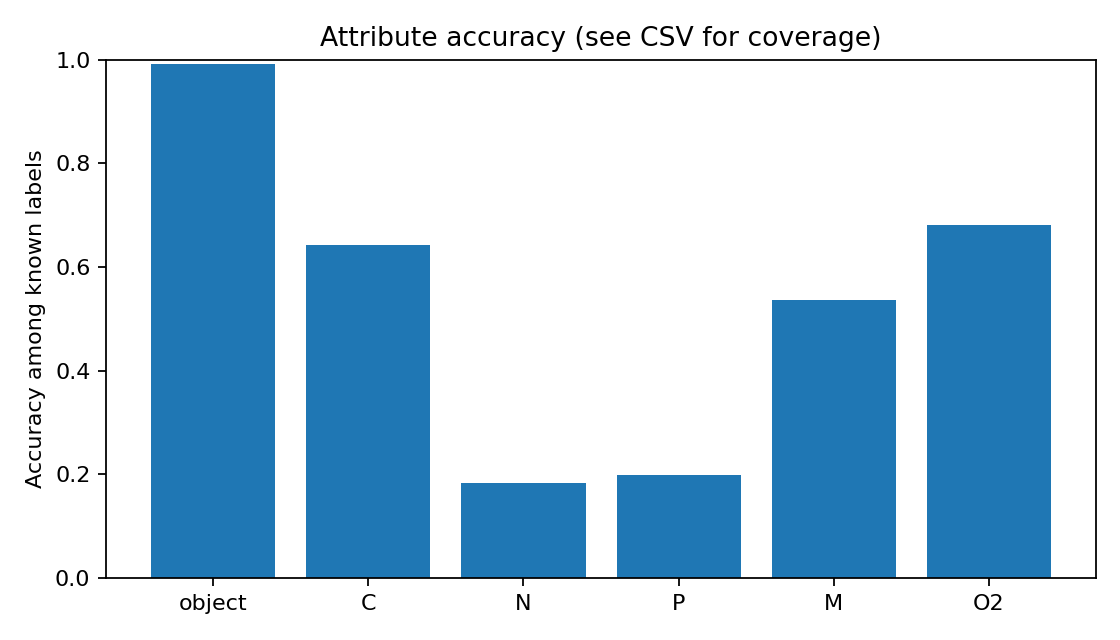

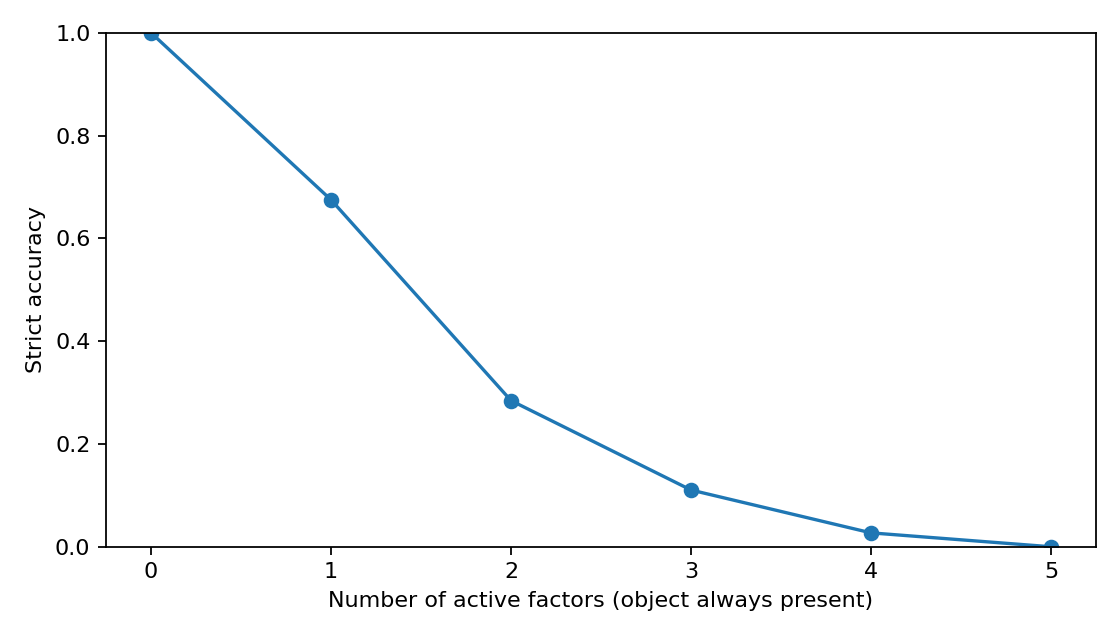

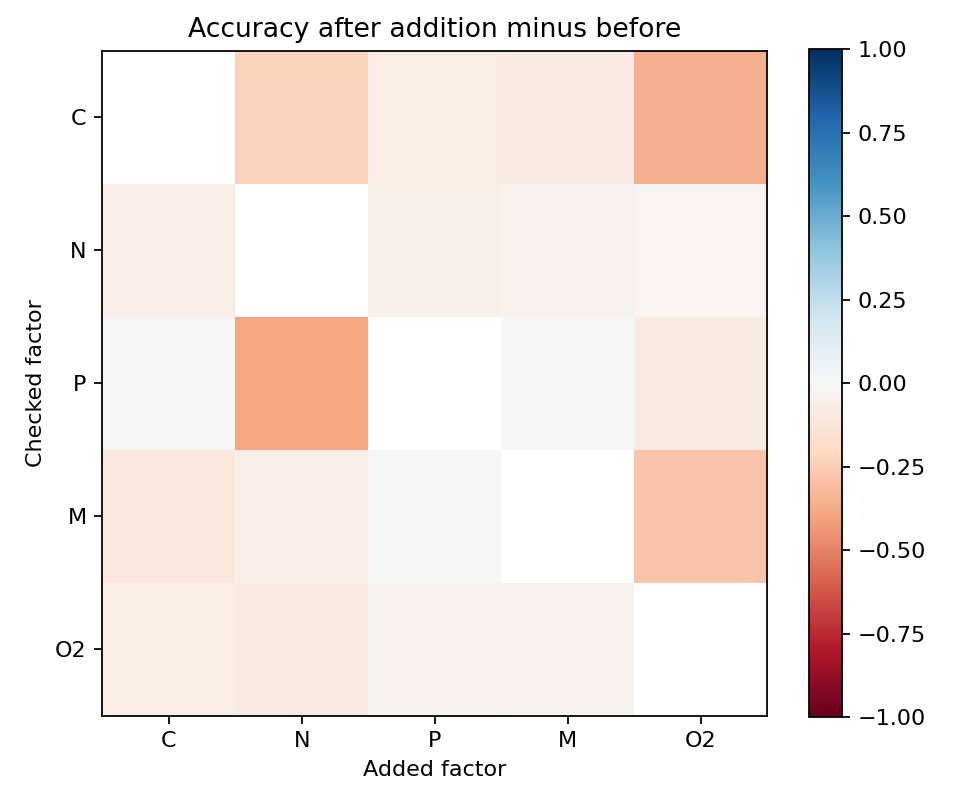

In [ ]:
evaluate_run("main_sdxl", "main_sdxl", "owl", every=25)
evaluate_run("main_sdxl", "main_sdxl", "qwen", every=25)
analyze_run("main_sdxl", "main_sdxl")

import pandas as pd
from attribute_interference.storage import read_csv
from IPython.display import display, Image as DisplayImage

MAIN_OUT = OUTPUTS / "main_sdxl" / f"analysis_qwen_{QUANT}"
summary = json.loads((MAIN_OUT / "summary.json").read_text())
print(json.dumps(summary["run"], indent=2))
display(pd.DataFrame(read_csv(MAIN_OUT / "attributes.csv")))
display(pd.DataFrame(read_csv(MAIN_OUT / "by_complexity.csv")))
for figure in ["attribute_accuracy.png", "complexity.png", "interference.png"]:
    display(DisplayImage(filename=str(MAIN_OUT / figure)))

In [ ]:
!ls /content/drive/MyDrive/attribute_interference/v1/main_sdxl/owl_records | wc -l
!ls /content/drive/MyDrive/attribute_interference/v1/main_sdxl/owl_records | head -5
!ps aux | grep -E "eval_quant|gen_sdxl|attribute_interference" | grep -v grep
!mount | grep drive

ls: cannot access '/content/drive/MyDrive/attribute_interference/v1/main_sdxl/owl_records': No such file or directory
0
ls: cannot access '/content/drive/MyDrive/attribute_interference/v1/main_sdxl/owl_records': No such file or directory
drive on /content/drive type fuse.drive (rw,nosuid,nodev,relatime,user_id=0,group_id=0)


In [ ]:
!ls /content/local_runs/main_sdxl/owl_records | wc -l
!ls /content/local_runs/main_sdxl/qwen_int8_records | wc -l
!ls -la /content/drive/MyDrive/attribute_interference/v1/main_sdxl/*.tar

745
997
ls: cannot access '/content/drive/MyDrive/attribute_interference/v1/main_sdxl/*.tar': No such file or directory


In [ ]:
import time, tarfile
DRIVE_OUTPUTS = Path("/content/drive/MyDrive/attribute_interference/v1")
dst = Path("/content/local_runs/main_sdxl")
archive = DRIVE_OUTPUTS / "main_sdxl" / f"eval_results_{time.strftime('%Y%m%d_%H%M')}.tar"
keep = ["owl_records", "qwen_int8_records", "models", "environment", "analysis",
        "analysis_qwen_int8", "labels.csv", "QWEN_INT8_NOTE.json", "PRELIMINARY_UNFROZEN.json"]
with tarfile.open(archive, "w") as tar:
    for name in keep:
        if (dst / name).exists():
            tar.add(dst / name, arcname=name)

In [ ]:
!ls -la /content/drive/MyDrive/attribute_interference/v1/main_sdxl/ | grep -E "tar|gsheet"
import tarfile
a = sorted(Path("/content/drive/MyDrive/attribute_interference/v1/main_sdxl").glob("eval_results_*.tar"))[-1]
names = tarfile.open(a).getnames()
print(a.name, len(names), "files")
print(sum(n.startswith("owl_records/") for n in names) - 1, "owl,",
      sum(n.startswith("qwen_int8_records/") for n in names) - 1, "qwen")